# 🏠 German Rental Price Classification: Final Evaluation
**Input:** the final Random Forest and the untouched test set, saved by `03_modeling.ipynb` (step 8.9).
**Rule:** the test set is the final exam. It is predicted **once**, and results are reported as they are (no further tuning).


## Imports
All tools used in this notebook. After a restart, run this cell first.


In [1]:
# --- Data and plots ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- Loading the saved model and test set ---
import joblib

# --- Evaluation measures ---
from sklearn.metrics import (
    accuracy_score,            # overall % correct
    balanced_accuracy_score,   # average recall of the 3 classes
    classification_report,     # precision, recall, F1 per class
    confusion_matrix,          # table of true vs predicted classes (step 9.2)
)

# Show numbers with 1 decimal instead of scientific notation
pd.set_option("display.float_format", "{:,.1f}".format)


## Load the final model and the test set


In [2]:
final_model    = joblib.load("../models/final_random_forest.joblib")   # the trained pipeline (prep + forest)
X_test, y_test = joblib.load("../models/test_set.joblib")              # the locked final exam

print("Test set:", X_test.shape)
print("Classes:", y_test.value_counts().sort_index().to_dict())


Test set: (53571, 23)
Classes: {'Low': 17873, 'Medium': 17841, 'High': 17857}


## 9.1 Final exam: overall and per-class scores
- **Accuracy:** % of test flats predicted correctly.
- **Precision:** when the model predicts a class, how often it is right (few false alarms).
- **Recall:** of the flats really in a class, how many it finds (few misses).
- **F1:** one number balancing precision and recall.
- **Balanced accuracy:** average recall of the 3 classes.


In [4]:
y_pred = final_model.predict(X_test)      # THE FINAL EXAM: predict every test flat, once

print(f"Test accuracy:          {accuracy_score(y_test, y_pred) * 100:.1f}%")
print(f"Test balanced accuracy: {balanced_accuracy_score(y_test, y_pred) * 100:.1f}%")


Test accuracy:          80.3%
Test balanced accuracy: 80.3%


In [5]:
print(classification_report(y_test, y_pred, labels=["Low", "Medium", "High"], digits=3))


              precision    recall  f1-score   support

         Low      0.853     0.831     0.842     17873
      Medium      0.709     0.715     0.712     17841
        High      0.847     0.863     0.854     17857

    accuracy                          0.803     53571
   macro avg      0.803     0.803     0.803     53571
weighted avg      0.803     0.803     0.803     53571



In [6]:
predictions = pd.DataFrame({"true": y_test, "predicted": y_pred}, index=y_test.index)
predictions.to_csv("../data/processed/test_predictions.csv")
print("Saved", len(predictions), "predictions")


Saved 53571 predictions


**Findings (9.1):**
- **Test accuracy 80.3%** (balanced accuracy 80.3%), slightly above the CV estimate (79.6% ± 0.2), as expected since the final model learned from all 214k training flats (vs ~171k per CV round). The estimate was honest; no overfitting to the validation set.
- **Easiest: High (F1 85.4%)**: its flats are distinctive (big cities, new builds, lifts, upscale interiors).
- **Hardest: Medium (F1 71.2%)**: it sits between Low and High and is the narrowest price band (€6.07–9.06), so small differences decide the class.
- **Balanced model:** precision ≈ recall for every class, and balanced accuracy = accuracy, so the model doesn't favour or avoid any class.


## 9.2 Confusion matrix
Rows = true class, columns = predicted class, each row as % of that class.
Diagonal = correct; next to it = near mistakes (acceptable); corners = **far mistakes (Low ↔ High), which must be rare** (Phase 1 criterion).


In [7]:
classes = ["Low", "Medium", "High"]

cm = confusion_matrix(y_test, y_pred, labels=classes, normalize="true") * 100   # each row as %
cm_table = pd.DataFrame(cm,
                        index=[f"true {c}" for c in classes],
                        columns=[f"pred {c}" for c in classes])
cm_table


,pred Low,pred Medium,pred High
true Low,83.1,15.9,1.0
true Medium,13.9,71.5,14.6
true High,0.4,13.3,86.3


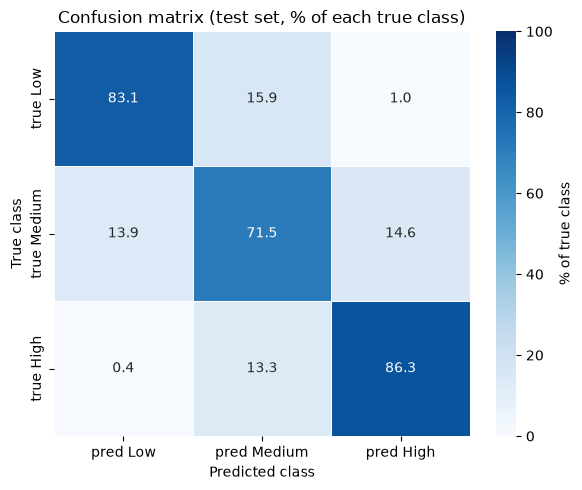

In [8]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_table, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100,
            cbar_kws={"label": "% of true class"}, linewidths=0.5, ax=ax)
ax.set_title("Confusion matrix (test set, % of each true class)")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
plt.tight_layout()
plt.savefig("../reports/figures/confusion_matrix.png", dpi=150)
plt.show()


In [9]:
far = (((y_test == "Low") & (y_pred == "High")) | ((y_test == "High") & (y_pred == "Low"))).mean() * 100
print(f"Far mistakes (Low ↔ High): {far:.2f}% of all test flats")


Far mistakes (Low ↔ High): 0.47% of all test flats


**Findings (9.2, confusion matrix):**
- **Diagonal = recall:** Low 83.1%, Medium 71.5%, High 86.3% (matches 9.1).
- **Near mistakes (one class off)** are the main error type: 13.3–15.9% per class. Medium's errors split evenly (13.9% → Low, 14.6% → High), so there is no bias towards cheaper or pricier predictions.
- **Far mistakes (Low ↔ High) are very rare:** 251 flats = **0.47%** of the test set (Low→High 1.0% of Low flats, High→Low 0.4% of High flats). About **98% of all mistakes are near mistakes**.
- ✅ **Phase 1 criterion met:** far mistakes are rare, so the platform would almost never label an expensive flat a "good deal" or vice versa.


## 9.3 Feature importance
Random Forest importance = how much each feature helped the trees separate the classes (all features sum to 100%).
One-hot columns (e.g. 146 `regio2_*` columns) are summed back into their original feature.
⚠️ This method slightly favours numeric and many-category features, so read it as a ranking.


In [ ]:
prep   = final_model.named_steps["prep"]     # the fitted preparation machine ,taken form our pipeline named_steps["prep"] picks the step called "prep", which is the fitted machine: it remembers the categories it learned.
forest = final_model.named_steps["model"]    # the fitted Random Forest- take random forest model from our pipeline,remember importance

names = prep.get_feature_names_out()         # the 220 column names, e.g. "cat__regio2_Berlin"
importance = pd.Series(forest.feature_importances_, index=names)

# return one-hot column name to the original column name, e.g. "cat__regio2_Berlin" → "regio2"
def original_feature(name):
    station, rest = name.split("__", 1)      # "cat__regio2_Berlin" → "cat", "regio2_Berlin"
    if station == "cat":                     # one-hot column → find which original column it came from
        return next(col for col in X_test.columns if rest.startswith(col + "_"))  
        # next return first col match
    return rest                              # number or yes/no column: the name is already original

by_feature = (importance.groupby(original_feature).sum() * 100).sort_values(ascending=False)
by_feature.round(1)


regio2            16.8
pricetrend        12.4
regio1             9.8
yearConstructed    7.2
livingSpace        6.4
condition          5.0
picturecount       4.3
heatingType        4.2
thermalChar        4.1
interiorQual       4.1
typeOfFlat         4.0
hasKitchen         3.3
petsAllowed        2.9
noRooms            2.9
floor              2.5
numberOfFloors     2.2
lift               2.0
balcony            1.1
cellar             1.1
hasParking         1.1
newlyConst         1.0
wasRefurbished     0.9
garden             0.8
dtype: float64

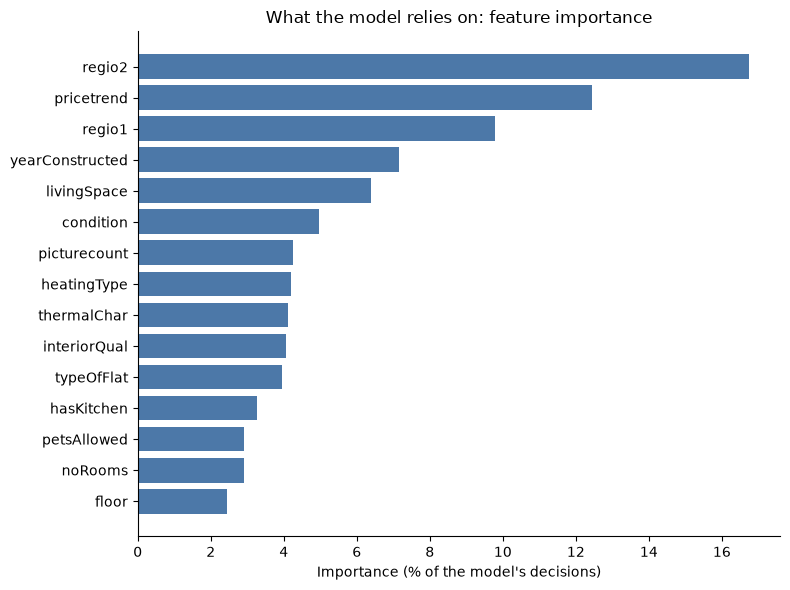

In [12]:
top = by_feature.head(15).sort_values()                # top 15, smallest first (so the biggest is at the top)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color="#4C78A8")
ax.set_title("What the model relies on: feature importance")
ax.set_xlabel("Importance (% of the model's decisions)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../reports/figures/feature_importance.png", dpi=150)
plt.show()


**Findings (9.3, feature importance):**
- **Location dominates:** `regio2` (16.8%), `pricetrend` (12.4%, an area-level trend) and `regio1` (9.8%) together drive ~39% of the model's decisions, matching the EDA (strongest Cramér's V).
- **Phase 4 hypotheses confirmed:** `regio1` (3rd), `yearConstructed` (4th, 7.2%), `livingSpace` (5th, 6.4%).
- **`livingSpace` matters more than its weak correlation (0.1) suggested:** trees can capture the **U-shape** found in EDA (small and large flats pricier per m²), which correlation misses. (Importance slightly favours numeric features, so the exact % may be inflated.)
- **Overlapping features share importance:** `newlyConst` (1.0%) despite its huge EDA effect, because `yearConstructed` already carries that information; similarly `lift` (2.0%).
- **Surprise:** `picturecount` (4.3%): listings with more photos tend to be pricier (likely more carefully presented upscale flats).
- **Negligible, as in EDA:** `garden` (0.8%, last), `cellar` (1.1%), `wasRefurbished` (0.9%).
- **Lesson:** low importance can mean "already covered by another feature", not necessarily "useless".


## 9.4 Error analysis
Which flats does the model get wrong, and why?
A. Are mistakes close to the class borders (€6.07 and €9.06 per m²)?
B. What do the 251 far mistakes (Low ↔ High) have in common?


In [13]:
df_clean    = pd.read_csv("../data/processed/immo_clean.csv")                 # to get each flat's real price per m²
predictions = pd.read_csv("../data/processed/test_predictions.csv", index_col=0)

errors = X_test.copy()
errors["true"]       = predictions["true"]
errors["pred"]       = predictions["predicted"]
errors["rentPerSqm"] = df_clean.loc[X_test.index, "rentPerSqm"]   # match each test flat by its index
errors["correct"]    = errors["true"] == errors["pred"]

print("Correct:", errors["correct"].sum(), " Wrong:", (~errors["correct"]).sum())


Correct: 43007  Wrong: 10564


## Close mistakes 

"Are most of the model's mistakes on flats that sit very close to a class border?"
        Low         │      Medium      │        High
  €2 ───────────── €6.07 ──────────── €9.06 ───────────── €40
                 border 1           border 2


        Low         │      Medium      │        High
  €2 ───────────── €6.07 ──────────── €9.06 ───────────── €40
                  cut1               cut2

In [ ]:
cut1, cut2 = df_clean["rentPerSqm"].quantile([1/3, 2/3])     # the two borders (≈ €6.07 and €9.06)


# calculate the distance of each flat from each cut and take min
errors["dist_to_border"] = np.minimum(
    (errors["rentPerSqm"] - cut1).abs(), 
    (errors["rentPerSqm"] - cut2).abs(),
)

print("Median distance to nearest border (€ per m²):")
# median gives typical distance in each group, so we can see how close the flats are to the borders when the model makes a mistake
print(errors.groupby("correct")["dist_to_border"].median().round(2))

near_border = errors["dist_to_border"] < 1           # within €1 of a border classefied as close to border classes
# ~errors['correct'] flips so when it is True the prediction is wrong, and when it is False the prediction is correct
print(f"\nShare of WRONG predictions within €1 of a border:   {near_border[~errors['correct']].mean() * 100:.1f}%") 
print(f"Share of CORRECT predictions within €1 of a border: {near_border[errors['correct']].mean() * 100:.1f}%")


Median distance to nearest border (€ per m²):
correct
False   0.6
True    1.1
Name: dist_to_border, dtype: float64

Share of WRONG predictions within €1 of a border:   73.2%
Share of CORRECT predictions within €1 of a border: 43.9%


WRONG flats (10,564)    = 100%  →  73.2% near a border  +  26.8% not near
CORRECT flats (43,007)  = 100%  →  43.9% near a border  +  56.1% not near


**Findings (9.4 A: mistakes and class borders):**
- **73.2% of wrong predictions** are within €1 of a class border (€6.07 or €9.06), compared with 43.9% of correct predictions. (Each % is of its own group, so they don't add up to 100%.)
- Wrong predictions are typically **€0.60** from a border vs **€1.10** for correct ones.
- Seen the other way: the error rate is **29%** for flats within €1 of a border vs **10.5%** for flats further away, about 3× higher.
- **Conclusion:** most mistakes are borderline "in-between" flats, where a few cents decide the class, not failures on clear-cut cases.


## Far mistakes

In [15]:
is_far = (((errors["true"] == "Low")  & (errors["pred"] == "High")) |
          ((errors["true"] == "High") & (errors["pred"] == "Low")))
far = errors[is_far]

print("Far mistakes:", len(far))
print("\nReal price per m² (median) by mistake type:")
print(far.groupby(["true", "pred"])["rentPerSqm"].median().round(2))
print("\nTypical price per m² of each class (all test flats):")
print(errors.groupby("true")["rentPerSqm"].median().round(2))


Far mistakes: 251

Real price per m² (median) by mistake type:
true  pred
High  Low    10.0
Low   High    5.5
Name: rentPerSqm, dtype: float64

Typical price per m² of each class (all test flats):
true
High     11.8
Low       5.2
Medium    7.3
Name: rentPerSqm, dtype: float64


In [16]:
cols = ["regio2", "livingSpace", "yearConstructed", "newlyConst", "interiorQual", "rentPerSqm", "true", "pred"]
far.sort_values("rentPerSqm")[cols].head(10)


,regio2,livingSpace,yearConstructed,newlyConst,interiorQual,rentPerSqm,true,pred
55297,other_Niedersachsen,94.0,"2,018.0",True,unknown,2.7,Low,High
9519,other_Niedersachsen,83.0,"2,018.0",True,sophisticated,2.8,Low,High
72013,Bielefeld,20.0,NaN,False,unknown,3.2,Low,High
152675,other_Bayern,170.0,"1,945.0",False,unknown,3.5,Low,High
179110,other_Bayern,56.7,"1,972.0",False,unknown,3.8,Low,High
108438,other_Baden_Württemberg,13.0,NaN,False,unknown,3.8,Low,High
95288,Bremen,80.0,"1,938.0",False,normal,4.0,Low,High
264843,other_Bayern,220.0,"2,016.0",False,normal,4.2,Low,High
257210,other_Brandenburg,77.0,"1,994.0",False,sophisticated,4.2,Low,High
138387,other_Bayern,125.0,"1,990.0",False,unknown,4.2,Low,High


### ⭐ The big insight: these "mistakes" are exactly what the platform wants to find
Go back to our goal from Phase 1. The platform compares the **predicted** class (what the features say the flat **should** cost) with the **actual** price:

| Mistake type | What it really means | Platform label |
|---|---|---|
| True **Low**, predicted **High** | Features say expensive, price is cheap | 💎 **Possible good deal**, or a data error to check |
| True **High**, predicted **Low** | Features say cheap, price is high | ⚠️ **Possibly overpriced** |

So for the business, many of these "mistakes" are **not failures**: they are the model **disagreeing with the price**, which is exactly the signal the platform needs.

> **The model's job is to say what a flat *should* cost based on its features. When the real price strongly disagrees, that flat deserves a closer look.**

**Caution:** the data alone cannot tell which far mistakes are real bargains or overpriced flats and which are data errors (e.g. a wrong size entered). A real platform would need a person to check a sample of them.


**Findings (9.4 B: the 251 far mistakes):**
- **True Low → predicted High** (median €5.50/m², close to a typical Low flat at €5.20): genuinely cheap flats whose features look expensive. Possible reasons: genuine bargains, subsidized housing, or data errors (e.g. size entered too large).
- **True High → predicted Low** (median €10.00/m², below a typical High flat at €11.80 and only ~€1 above the border): flats priced high despite "cheap" features. Possible reasons: overpriced listings, or qualities missing from the data (view, renovation, exact street).
- **Business meaning:** these disagreements are exactly what the platform wants to flag: features say one price level, the actual price says another (💎 possible good deal / ⚠️ possibly overpriced).
- **Caution:** the data alone cannot separate real bargains or overpricing from data errors; a platform would need to manually check a sample.


## 9.5 Success criteria check (set in Phase 1, before seeing the data)

| Criterion (Phase 1) | Target | Result (test set) | Met? |
|---|---|---|---|
| Beat the baseline | > 33.4% | **80.3%** (+46.9 points) | ✅ |
| **Main goal: accuracy** | **≥ 70%** | **80.3%** | ✅ |
| Classes balanced (accuracy is a valid measure) | ~33% each | 33.4 / 33.3 / 33.3% | ✅ |
| **Far mistakes (Low ↔ High) rare** | Rare | **0.47%** of flats; ~98% of errors are near mistakes | ✅ |
| Per-class precision / recall / F1 reported | Reported | F1: Low 84.2%, Medium 71.2%, High 85.4% | ✅ |
| No class predicted badly | — | Weakest is Medium (71.2%), still above 70% | ✅ |

**All success criteria are met.**


### Limitations
- **Medium is the hardest class (F1 71.2%):** it is the narrowest price band (€6.07–9.06), and most mistakes are borderline flats within €1 of a class border.
- **Missing information:** the data lacks factors that clearly affect rent: exact street or micro-location, view, true renovation quality, and the listing text (`description`, `facilities` were dropped).
- **Far mistakes cannot be explained by data alone:** some may be genuine bargains or overpriced flats, others data errors (e.g. a wrong size); a platform would need manual checks.
- **Time:** the data covers listings from 2018–2020. Rents change, so the model (and the class borders) would need retraining on newer data before real use.
- **Price classes, not prices:** the model predicts a band (Low/Medium/High), not an exact rent.


### 9.6 Phase 9 summary
- **Final model:** Random Forest (100 trees, default settings, median filling), trained on all ~214k training flats.
- **Test accuracy: 80.3%** (balanced accuracy 80.3%), above the 70% goal and the CV estimate (79.6% ± 0.2).
- **Errors:** mostly borderline flats (73% of errors within €1 of a border); far mistakes only 0.47%.
- **Drivers:** location (`regio2`, `pricetrend`, `regio1` ≈ 39% of importance), then year built and living space.
- **Business value:** disagreements between predicted and actual class are exactly the "good deal" / "possibly overpriced" signals the platform needs.
